# GDGoC UGM Academic Hacker 2026
## Prediksi diagnosis infeksi saluran napas dari riwayat medis dan triase

**Tugas.** Memprediksi salah satu dari 4 diagnosis untuk setiap encounter: `viral_sinusitis`, `viral_pharyngitis`, `acute_bronchitis`, atau `strep_pharyngitis`. Metrik penilaian: **Macro F1**.

**Ringkasan hasil**

| Model | Macro F1 (validasi silang 5-fold) |
|---|---|
| Baseline Logistic Regression | 0,626 |
| LightGBM (argmax) | 0,669 |
| LightGBM + bobot kelas (in-sample) | 0,694 |
| LightGBM + bobot kelas (split-half, lebih jujur) | sekitar 0,682 (0,669 + 0,013) |

**Alur notebook**

1. **Masalah awal dataset**: daftar masalah yang ditemukan sebelum pemodelan, beserta cara penanganannya.
2. **Persiapan dan muat data**: membaca 17 tabel dan memahami strukturnya.
3. **Masalah 1, aturan waktu**: memastikan model tidak melihat data dari masa depan.
4. **Masalah 2 dan 3, format dan nilai**: membersihkan angka, satuan, dan nilai yang tidak masuk akal.
5. **Masalah 4, pendapatan**: menyamakan format uang.
6. **Membangun fitur**: satu sumber data per sel.
7. **Validasi fitur**: membandingkan hasil pipeline dengan perhitungan langsung dari data mentah.
8. **Pemodelan**: baseline, pencarian hyperparameter, dan optimasi bobot kelas.
9. **Evaluasi dan submission**.
10. **Interpretasi dan keterbatasan**.

Setiap sel hanya mengerjakan satu proses. Penjelasan ada di markdown sebelum setiap sel.

## 1. Masalah awal dataset

Sebelum membangun model, saya memeriksa data dan menemukan beberapa masalah. Setiap masalah punya bukti yang bisa dilihat di bagian yang disebutkan.

| No | Masalah | Bukti | Penanganan | Bagian |
|---|---|---|---|---|
| 1 | Data tersebar di 17 tabel dengan relasi satu-ke-banyak | Tabel riwayat punya banyak baris per pasien | Diringkas menjadi satu baris per pasien/encounter | 2, 6 |
| 2 | Risiko kebocoran waktu: data riwayat bisa setelah prediksi dibuat | Setiap encounter punya `prediction_time` | Hanya event yang tersedia sebelum cutoff yang dipakai | 3 |
| 3 | Data triase tampak berada setelah cutoff | Hampir semua timestamp triase > `prediction_time` | Diuji: selisihnya hanya di bawah 1 detik, jadi dianggap bersamaan | 3 |
| 4 | Angka memakai koma desimal | Contoh `18,33` dan `0,9` pada vital | Koma diubah menjadi titik | 4 |
| 5 | Satuan campur untuk konsep yang sama | SpO2 dalam `%` dan `fraction`; tekanan darah dalam `mmHg` dan `kPa` | Disamakan ke satu satuan | 4 |
| 6 | Nilai tidak masuk akal | BMI 304, sistolik 1390, detak jantung 990 | Di luar rentang klinis dijadikan kosong (tidak ditebak) | 4 |
| 7 | Pendapatan dalam banyak format | `13.1k`, `20,982`, `USD 122,462`, `$51,777` | Dinormalisasi ke satu skala angka | 5 |
| 8 | Kelas target tidak seimbang | `strep_pharyngitis` hanya 5,4% | Bobot kelas saat latih dan tuning bobot untuk Macro F1 | 9 |
| 9 | Tidak ada hasil tes strep (antigen cepat atau kultur) | Tidak ada observasi terkait | Tercatat sebagai keterbatasan | 10 |
| 10 | Keluhan utama tidak punya timestamp | Kolom waktu tidak tersedia | Diasumsikan dicatat saat triase | 6 |
| 11 | Nama kolom mengandung karakter khusus | Contoh `Heart rate`, `[Score]` | Nama dibersihkan, tabrakan diberi akhiran | 6 |
| 12 | Pasien tanpa catatan harus dibedakan dari nilai nol | Kosong bisa berarti "tidak ada" atau "tidak diketahui" | Hitungan diisi 0; nilai numerik dibiarkan kosong | 6 |

## 2. Persiapan dan muat data

Kode di sel berikut mencari folder data secara otomatis. Notebook mencari folder yang berisi `index_encounters.csv`, `train.csv`, `test.csv`, dan `sample_submission.csv`, dimulai dari folder kerja dan folder induknya.

Jika deteksi gagal, isi `DATA_DIR_OVERRIDE` dengan path folder data.

In [1]:
import os, glob, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix, f1_score, log_loss
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})

# Konstanta yang dipakai di seluruh notebook
SEED = 42
N_SPLITS = 5
N_TRIALS = 12
MIN_COUNT = 20
ONE_SEC = pd.Timedelta(seconds=1)
ID_COLS = ["sample_id", "patient_id", "encounter_id"]
TARGET = "target_class"
CATEGORICAL = ["gender", "race", "ethnicity", "state", "marital_at_visit"]
VITAL_RANGES = {"Heart rate": (20, 250), "Respiratory rate": (4, 60), "Systolic BP": (50, 260),
                "Diastolic BP": (30, 160), "SpO2": (50, 100), "BMI": (10, 80)}
OBS_RANGES = {"Systolic Blood Pressure": (50, 260), "Diastolic Blood Pressure": (30, 160),
              "Heart rate": (20, 250), "Respiratory rate": (4, 60),
              "Body mass index (BMI) [Ratio]": (10, 80), "Body Weight": (2, 300),
              "Pain severity - 0-10 verbal numeric rating [Score] - Reported": (0, 10),
              "Patient Health Questionnaire 2 item (PHQ-2) total score [Reported]": (0, 6)}
HISTORY = {"conditions": ("condition_code", "cond"), "medications": ("medication_code", "med"),
           "procedures": ("procedure_code", "proc"), "immunizations": ("immunization_code", "imm"),
           "allergies": ("allergy_code", "alg")}
GRID = np.exp(np.linspace(np.log(0.5), np.log(2.0), 21))

In [2]:
REQUIRED = {"index_encounters.csv", "train.csv", "test.csv", "sample_submission.csv"}
DATA_DIR_OVERRIDE = None   # contoh Windows: r"C:\Users\nama\Project\gdgoc-ugm-academic-hacker-2026"

if DATA_DIR_OVERRIDE:
    DATA_DIR = DATA_DIR_OVERRIDE
else:
    base = os.path.abspath(os.getcwd())
    roots = [base, os.path.dirname(base), os.path.dirname(os.path.dirname(base)), "/kaggle/input"]
    candidates = []
    for r in roots:
        if os.path.isdir(r):
            candidates.append(r)
            for e1 in os.scandir(r):
                if e1.is_dir():
                    candidates.append(e1.path)
                    candidates += [e2.path for e2 in os.scandir(e1.path) if e2.is_dir()]
    DATA_DIR = next((c for c in candidates if REQUIRED <= set(os.listdir(c))), None)

assert DATA_DIR is not None, "Folder data tidak ditemukan. Isi DATA_DIR_OVERRIDE."
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.join(os.getcwd(), "output")
os.makedirs(OUT_DIR, exist_ok=True)
print("Folder data :", DATA_DIR)
print("Folder output:", OUT_DIR)

Folder data : C:\INAH-MINE\GEMASTIK-XIX\gdgoc-ugm-academic-hacker-2026
Folder output: C:\INAH-MINE\GEMASTIK-XIX\gdgoc_claude\output


### Memuat semua tabel

Semua CSV dibaca ke dalam satu kamus `T`, dengan nama file sebagai kunci. `DATA_DICTIONARY` dilewati karena itu metadata.

In [3]:
T = {}
for f in sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)):
    name = os.path.splitext(os.path.basename(f))[0]
    if name != "DATA_DICTIONARY":
        T[name] = pd.read_csv(f)
print(f"{len(T)} tabel dimuat")

16 tabel dimuat


### Ringkasan tabel

Setiap tabel punya grain (apa yang diwakili satu baris) yang berbeda. Tabel indeks dan sampel punya satu baris per encounter. Tabel riwayat punya banyak baris per pasien. Perbedaan ini menentukan cara penggabungan.

In [4]:
rows = []
for name, df in T.items():
    rows.append({"tabel": name, "baris": len(df), "kolom": df.shape[1],
                 "pasien unik": df["patient_id"].nunique() if "patient_id" in df else None,
                 "encounter unik": df["encounter_id"].nunique() if "encounter_id" in df else None})
pd.DataFrame(rows).sort_values("baris", ascending=False).reset_index(drop=True)

,tabel,baris,kolom,pasien unik,encounter unik
0,observations,55648,9,1895.0,NaN
1,triage_vitals,30000,6,5000.0,5000.0
2,triage_symptoms,19065,4,5000.0,5000.0
3,procedures,17024,6,3111.0,NaN
4,triage_symptom_severity,16594,5,4961.0,4961.0
5,index_encounters,5000,3,5000.0,5000.0
6,presenting_complaints,5000,3,5000.0,5000.0
7,patients,5000,10,5000.0,NaN
8,previous_encounter,4471,7,4471.0,NaN
9,train,3600,4,3600.0,3600.0


### Target: distribusi kelas

Kelas `viral_sinusitis` mendominasi. `strep_pharyngitis` hanya sekitar 5%. Ketidakseimbangan ini mempengaruhi cara model dilatih dan cara bobot kelas dipilih, yang dibahas di bagian 8.

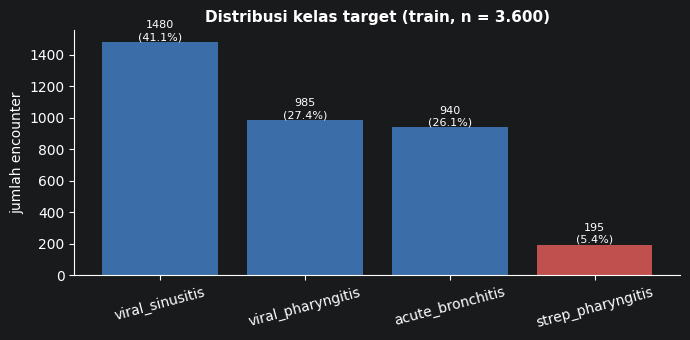

In [5]:
counts = T["train"][TARGET].value_counts()
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(counts.index, counts.values, color=["#3b6ea8", "#3b6ea8", "#3b6ea8", "#c0504d"])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v}\n({v/counts.sum():.1%})", ha="center", va="bottom", fontsize=8)
ax.set_title("Distribusi kelas target (train, n = 3.600)")
ax.set_ylabel("jumlah encounter")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

## 3. Masalah 1: aturan waktu (point-in-time)

Model hanya boleh memakai data yang sudah tersedia saat prediksi dibuat. Waktu prediksi ditulis di kolom `prediction_time`. Setiap event (misalnya kondisi, obat, atau hasil triase) punya timestamp sendiri. Event yang terjadi setelah `prediction_time` tidak boleh dipakai.

Pertama, saya membentuk tabel **universe**: satu baris per encounter, dengan `cutoff` berisi `prediction_time` yang dipotong ke detik.

In [6]:
idx = T["index_encounters"][["patient_id", "encounter_id", "prediction_time"]].copy()
idx["cutoff"] = pd.to_datetime(idx["prediction_time"], utc=True, format="ISO8601").dt.floor("s")
universe = idx[["patient_id", "encounter_id", "cutoff"]].reset_index(drop=True)
enc2pat = universe.set_index("encounter_id")["patient_id"]

print("Jumlah encounter:", len(universe))
print("Cutoff unik     :", universe["cutoff"].nunique())
universe.head()

Jumlah encounter: 5000
Cutoff unik     : 5000


,patient_id,encounter_id,cutoff
0,Pf4006ec4e7cd1bf39de6,E642a8a03cfd88867fb71,2025-12-07 10:54:34+00:00
1,Pc580785372db7a2c0869,E823e5290604e1ac12faa,2026-06-19 20:52:28+00:00
2,P02890b0cdc281646c45d,E5a9089bda12e5583f470,2025-04-29 21:40:55+00:00
3,P3fb55946e23fe5ebd83c,Ec799296abdf95b7337a7,2024-10-24 04:16:29+00:00
4,P4f60eff808ace6f388d1,E285b40bf18ee71650cb4,2026-04-15 22:13:34+00:00


### Apakah data triase setelah cutoff?

Jika dibandingkan secara langsung, hampir semua timestamp triase tampak lebih besar daripada `prediction_time`. Pertanyaannya: apakah ini kebocoran, atau hanya selisih kecil akibat pembulatan?

Histogram di bawah menunjukkan selisih dalam detik. Nilai 0 berarti sama persis, dan nilai di bawah 1 berarti masih dalam detik yang sama.

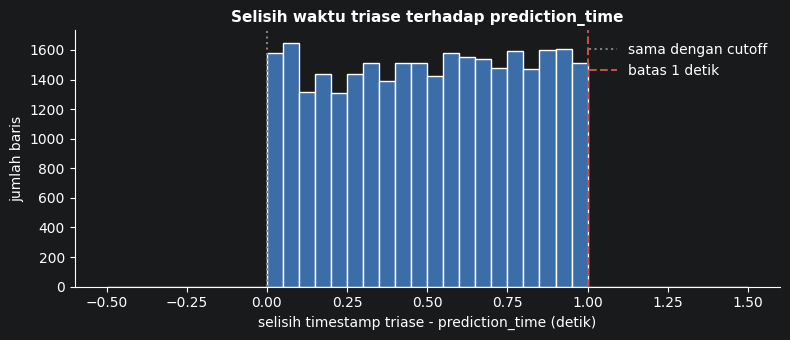

Min selisih : 0.000 detik
Maks selisih: 0.999 detik
Baris di dalam [0, 1) detik: 100.00%


In [7]:
vt = T["triage_vitals"].merge(universe[["encounter_id", "cutoff"]], on="encounter_id", how="inner")
vt["ts"] = pd.to_datetime(vt["measured_at"], utc=True, format="ISO8601")
delta = (vt["ts"] - vt["cutoff"]).dt.total_seconds()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(delta, bins=np.linspace(-0.5, 1.5, 41), color="#3b6ea8", edgecolor="white")
ax.axvline(0, color="grey", ls=":", label="sama dengan cutoff")
ax.axvline(1, color="#c0504d", ls="--", label="batas 1 detik")
ax.set_xlabel("selisih timestamp triase - prediction_time (detik)")
ax.set_ylabel("jumlah baris")
ax.set_title("Selisih waktu triase terhadap prediction_time")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

print(f"Min selisih : {delta.min():.3f} detik")
print(f"Maks selisih: {delta.max():.3f} detik")
print(f"Baris di dalam [0, 1) detik: {((delta >= 0) & (delta < 1)).mean():.2%}")

**Pembacaan grafik.** Seluruh selisih berada di antara 0 dan 1 detik. Ini berarti `prediction_time` adalah timestamp triase yang dipotong ke detik. Triase dicatat **pada saat prediksi dibuat**, bukan setelahnya. Selisih sub-detik tidak berarti kebocoran.

Kita perlu memastikan hal ini dengan uji langsung, yaitu memotong timestamp triase ke detik dan membandingkannya dengan `prediction_time`.

In [8]:
checks = []
for name, col in [("triage_vitals", "measured_at"), ("triage_symptoms", "observed_at"),
                  ("triage_symptom_severity", "observed_at")]:
    d = T[name].merge(universe[["encounter_id", "cutoff"]], on="encounter_id", how="inner")
    ts = pd.to_datetime(d[col], utc=True, format="ISO8601")
    checks.append({"tabel": name, "baris": len(d),
                   "floor(timestamp, detik) = prediction_time": f"{(ts.dt.floor('s') == d['cutoff']).mean():.2%}"})
pd.DataFrame(checks)

,tabel,baris,"floor(timestamp, detik) = prediction_time"
0,triage_vitals,30000,100.00%
1,triage_symptoms,19065,100.00%
2,triage_symptom_severity,16594,100.00%


### Dua aturan waktu: strict dan same-second

- **Strict**: event dianggap tersedia jika terjadi sebelum `cutoff`.
- **Same-second**: event dianggap tersedia jika terjadi sebelum `cutoff + 1 detik`. Dengan aturan ini, event di detik yang sama tetap dipakai.

Grafik berikut membandingkan jumlah baris yang lolos dengan kedua aturan. Aturan strict akan membuang semua data triase, sedangkan aturan same-second mempertahankannya.

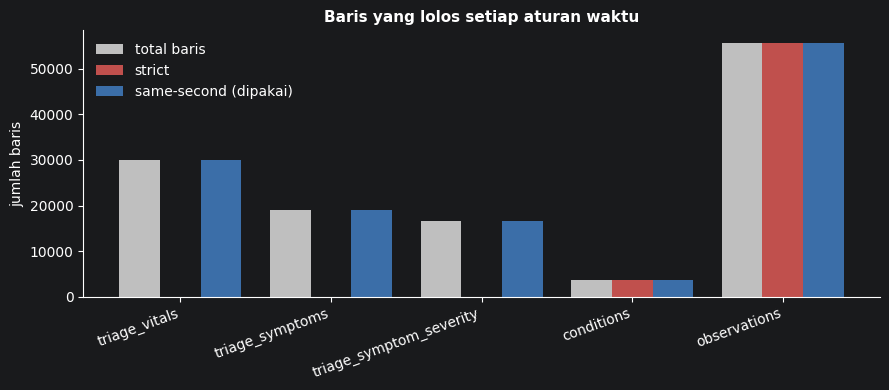

,tabel,total,strict (< cutoff),same-second (< cutoff + 1 detik)
0,triage_vitals,30000,0,30000
1,triage_symptoms,19065,0,19065
2,triage_symptom_severity,16594,0,16594
3,conditions,3583,3583,3583
4,observations,55648,55648,55648


In [9]:
comp = []
for name, col, key in [("triage_vitals", "measured_at", "encounter_id"),
                       ("triage_symptoms", "observed_at", "encounter_id"),
                       ("triage_symptom_severity", "observed_at", "encounter_id"),
                       ("conditions", "recorded_at", "patient_id"),
                       ("observations", "observed_at", "patient_id")]:
    d = T[name].merge(universe[[key, "cutoff"]], on=key, how="inner")
    ts = pd.to_datetime(d[col], utc=True, format="ISO8601")
    comp.append({"tabel": name, "total": len(d),
                 "strict (< cutoff)": int((ts < d["cutoff"]).sum()),
                 "same-second (< cutoff + 1 detik)": int((ts < d["cutoff"] + ONE_SEC).sum())})
comp = pd.DataFrame(comp)

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(comp)); wdt = 0.27
ax.bar(x - wdt, comp["total"], wdt, label="total baris", color="#bfbfbf")
ax.bar(x, comp["strict (< cutoff)"], wdt, label="strict", color="#c0504d")
ax.bar(x + wdt, comp["same-second (< cutoff + 1 detik)"], wdt, label="same-second (dipakai)", color="#3b6ea8")
ax.set_xticks(x); ax.set_xticklabels(comp["tabel"], rotation=20, ha="right")
ax.set_ylabel("jumlah baris"); ax.set_title("Baris yang lolos setiap aturan waktu")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
comp

**Keputusan.** Aturan **same-second** dipakai. Aturan strict membuang seluruh data triase, sehingga fitur triase, yang terbukti penting pada eksperimen, akan hilang.

Untuk tabel riwayat, kedua aturan memberi hasil yang sama, karena tidak ada event riwayat yang terjadi setelah cutoff. Hal ini diverifikasi di sel berikut.

In [10]:
hist_check = []
for name, col in [("conditions", "recorded_at"), ("medications", "recorded_at"),
                  ("procedures", "recorded_at"), ("observations", "observed_at"),
                  ("previous_encounter", "history_start")]:
    key = "patient_id"
    d = T[name].merge(universe[[key, "cutoff"]], on=key, how="inner")
    ts = pd.to_datetime(d[col], utc=True, format="ISO8601")
    hist_check.append({"tabel": name, "baris": len(d),
                       "baris setelah cutoff": int((ts > d["cutoff"]).sum()),
                       "baris dalam 1 detik setelah cutoff": int(((ts > d["cutoff"]) & (ts < d["cutoff"] + ONE_SEC)).sum())})
pd.DataFrame(hist_check)

,tabel,baris,baris setelah cutoff,baris dalam 1 detik setelah cutoff
0,conditions,3583,0,0
1,medications,3467,0,0
2,procedures,17024,0,0
3,observations,55648,0,0
4,previous_encounter,4471,0,0


## 4. Masalah 2 dan 3: format angka, satuan, dan nilai tidak masuk akal

Tabel vital dan observasi punya tiga masalah:
1. Angka memakai koma sebagai desimal (`18,33`), sehingga tidak bisa dibaca langsung sebagai angka.
2. Satuan campur untuk konsep yang sama.
3. Ada nilai yang tidak masuk akal, yang kemungkinan besar salah input.

Pertama, saya memeriksa pasangan nama vital dan satuannya.

In [11]:
vit = T["triage_vitals"].copy()
pd.crosstab(vit["vital_name"], vit["unit"])

unit,%,/min,beats/min,breaths/min,fraction,kPa,kg/m2,mmHg
vital_name,,,,,,,,
BMI,0,0,0,0,0,0,5000,0
Diastolic BP,0,0,0,0,0,317,0,4683
Heart rate,0,4333,667,0,0,0,0,0
Respiratory rate,0,4338,0,662,0,0,0,0
SpO2,4569,0,0,0,431,0,0,0
Systolic BP,0,0,0,0,0,301,0,4699


**Pembacaan tabel.** Dua vital memakai dua satuan:
- **SpO2** dengan `%` (normal) dan `fraction` (pecahan, misalnya 0,96 untuk 96%).
- **Tekanan darah** dengan `mmHg` (normal) dan `kPa` (misalnya 16 kPa sama dengan sekitar 120 mmHg).

Langkah pertama adalah mengubah koma menjadi titik, lalu membaca angka.

In [12]:
vit["value"] = (vit["value"].astype("string").str.strip()
                .str.replace(",", ".", regex=False))
vit["value"] = pd.to_numeric(vit["value"], errors="coerce").astype(float)
print("Nilai vital yang tadinya berkoma:", int(T["triage_vitals"]["value"].astype("string").str.contains(",", na=False).sum()))
print("Nilai vital yang kosong setelah dibaca:", int(vit["value"].isna().sum()))

Nilai vital yang tadinya berkoma: 112
Nilai vital yang kosong setelah dibaca: 3320


Boxplot di bawah memperlihatkan distribusi setiap pasangan vital dan satuan dengan skala logaritmik. Perhatikan:
- Sistolik dalam `kPa` berada di sekitar 16 (rata-rata), sedangkan dalam `mmHg` sekitar 123. Keduanya adalah konsep yang sama dalam satuan berbeda.
- Beberapa nilai ekstrem jauh di atas batas wajar, misalnya di atas 300 untuk tekanan darah.

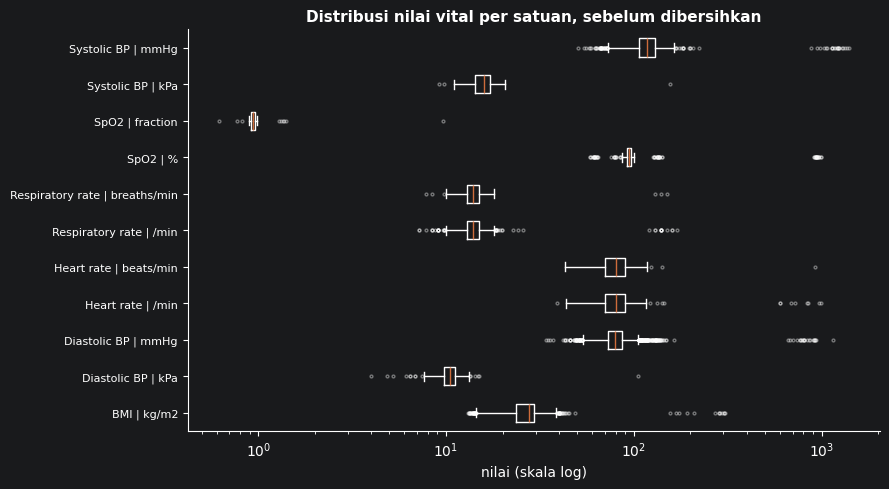

In [13]:
pairs = vit.dropna(subset=["value"]).groupby(["vital_name", "unit"])
labels, data = [], []
for (name, unit), g in pairs:
    labels.append(f"{name} | {unit}")
    data.append(g["value"].values)

fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(data, vert=False, showfliers=True, flierprops={"markersize": 2, "alpha": 0.4})
ax.set_yticks(range(1, len(labels) + 1)); ax.set_yticklabels(labels, fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("nilai (skala log)")
ax.set_title("Distribusi nilai vital per satuan, sebelum dibersihkan")
plt.tight_layout(); plt.show()

### Menyamakan satuan

- SpO2 dengan satuan `fraction` dikali 100, sehingga 0,96 menjadi 96.
- Tekanan darah dengan satuan `kPa` dikali 7,50062 untuk menjadi mmHg.

Setelah itu, nilai yang berada di luar rentang klinis dihitung. Nilai tersebut tidak diperbaiki dengan tebakan, tetapi dijadikan kosong (`NaN`). Grafik batang menunjukkan jumlahnya untuk setiap vital.

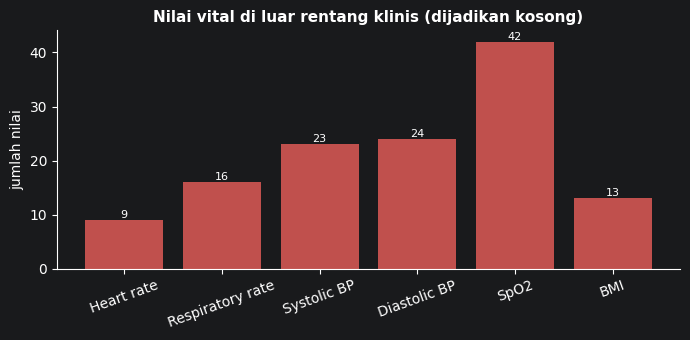

Total nilai yang dijadikan kosong: 127


In [14]:
m = (vit["vital_name"] == "SpO2") & (vit["unit"] == "fraction")
vit.loc[m, "value"] = vit.loc[m, "value"] * 100
m = vit["vital_name"].isin(["Systolic BP", "Diastolic BP"]) & (vit["unit"] == "kPa")
vit.loc[m, "value"] = vit.loc[m, "value"] * 7.50062

out_counts = {}
for name, (lo, hi) in VITAL_RANGES.items():
    m = (vit["vital_name"] == name) & vit["value"].notna() & ((vit["value"] < lo) | (vit["value"] > hi))
    out_counts[name] = int(m.sum())
    vit.loc[m, "value"] = np.nan

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(out_counts.keys(), out_counts.values(), color="#c0504d")
for i, v in enumerate(out_counts.values()):
    ax.text(i, v, str(v), ha="center", va="bottom", fontsize=8)
ax.set_title("Nilai vital di luar rentang klinis (dijadikan kosong)")
ax.set_ylabel("jumlah nilai")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()
print("Total nilai yang dijadikan kosong:", sum(out_counts.values()))

**Catatan.** Batas rentang berasal dari pengetahuan klinis umum, bukan dokumen resmi. Batas ini dipilih supaya nilai yang jelas salah input tertangkap, sementara nilai ekstrem yang mungkin benar tetap dipertahankan.

## 5. Masalah 4: pendapatan dalam format campuran

Kolom `income_at_visit` punya beberapa format. Koma di sini adalah **pemisah ribuan**, berbeda dengan koma pada vital yang adalah desimal. Karena itu aturannya tidak boleh disamakan.

Grafik batang menunjukkan jenis format yang ditemukan.

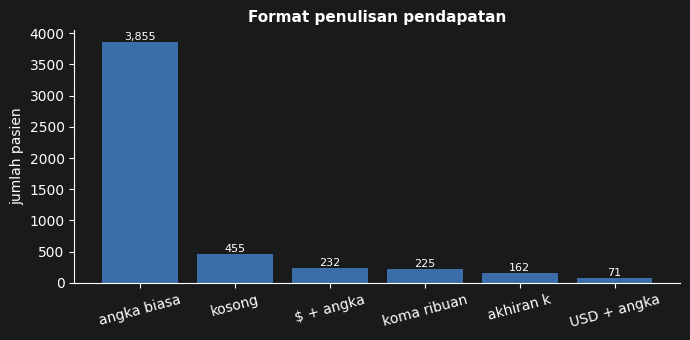

In [15]:
raw = T["patients"]["income_at_visit"].astype("string")
conds = [raw.str.contains("USD", na=False), raw.str.contains("$", regex=False, na=False),
         raw.str.contains("k", case=False, na=False), raw.str.contains(",", na=False)]
labels_fmt = ["USD + angka", "$ + angka", "akhiran k", "koma ribuan"]
fmt = pd.Series(np.select(conds, labels_fmt, default="angka biasa"))
fmt = fmt.where(raw.notna(), "kosong")
fc = fmt.value_counts()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(fc.index, fc.values, color="#3b6ea8")
for i, v in enumerate(fc.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
ax.set_title("Format penulisan pendapatan")
ax.set_ylabel("jumlah pasien")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

In [16]:
s = (raw.str.upper().str.replace("USD", "", regex=False).str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False).str.strip())
kilo = s.str.endswith("K").fillna(False).astype(bool)
patients = T["patients"].copy()
patients["income"] = pd.to_numeric(s.str.replace(r"K$", "", regex=True), errors="coerce") * np.where(kilo, 1000.0, 1.0)
patients["log_income"] = np.log1p(patients["income"])

unparsed = int((patients["income"].isna() & patients["income_at_visit"].notna()).sum())
print("Pendapatan kosong        :", int(patients["income_at_visit"].isna().sum()))
print("Pendapatan gagal dibaca  :", unparsed)

Pendapatan kosong        : 455
Pendapatan gagal dibaca  : 0


Setelah dinormalisasi, distribusi pendapatan dipetakan dengan skala logaritmik. Pendapatan biasanya miring ke kanan, sehingga logaritma membuat distribusinya lebih mudah dibaca dan lebih stabil untuk model.

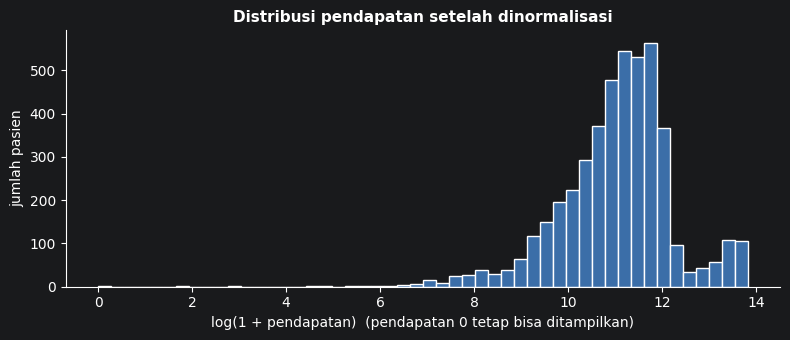

In [17]:
inc = patients["income"].dropna()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(np.log1p(inc), bins=50, color="#3b6ea8", edgecolor="white")
ax.set_xlabel("log(1 + pendapatan)  (pendapatan 0 tetap bisa ditampilkan)")
ax.set_ylabel("jumlah pasien")
ax.set_title("Distribusi pendapatan setelah dinormalisasi")
plt.tight_layout(); plt.show()

## 6. Membangun fitur

Fitur dibangun satu sumber data per sel. Semua fitur akhirnya disusun per pasien, karena setiap pasien punya tepat satu encounter.

Aturan yang dipakai:
- Event hanya dipakai jika tersedia pada cutoff (aturan same-second dari bagian 3).
- Kode yang muncul kurang dari 20 kali tidak dijadikan kolom, karena terlalu jarang untuk dipelajari model.
- Pasien tanpa catatan untuk suatu kode mendapat nilai 0 pada kolom biner. Untuk kolom hitungan, nilainya juga 0. Kolom jarak waktu dibiarkan kosong, karena 0 pada kolom itu berarti "baru saja terjadi".

Empat fungsi kecil dipakai berulang. Fungsi-fungsi ini didefinisikan dulu supaya setiap sel berikutnya pendek dan mudah dibaca.

In [18]:
def apply_cutoff(df, key, time_col, uni):
    """Pasang cutoff lewat key, lalu simpan hanya event yang tersedia (<= cutoff + 1 detik)."""
    d = df.merge(uni[[key, "cutoff"]], on=key, how="inner", validate="many_to_one")
    d["ts"] = pd.to_datetime(d[time_col], utc=True, format="ISO8601", errors="coerce")
    d = d[d["ts"] < d["cutoff"] + ONE_SEC].copy()
    d["days_before"] = ((d["cutoff"] - d["ts"]).dt.total_seconds() / 86400).clip(lower=0)
    return d


def recency(df, key, prefix):
    """Jumlah event dan jarak hari ke event terbaru sebelum cutoff."""
    g = df.groupby(key)
    return pd.DataFrame({f"{prefix}_n": g.size(),
                         f"{prefix}_days_since_last": g["days_before"].min()})


def code_flags(df, key, col, prefix):
    """Satu kolom biner per kode: 1 jika kode itu ada untuk key tersebut. Hanya kode yang cukup sering."""
    counts = df[col].value_counts()
    d = df[df[col].isin(counts[counts >= MIN_COUNT].index)]
    if d.empty:
        return pd.DataFrame(index=pd.Index([], name=key))
    flags = (pd.crosstab(d[key], d[col]) > 0).astype(np.int8)
    flags.columns = [f"{prefix}__{c}" for c in flags.columns]
    return flags


def per_code_stats(df, key, code_col, value_col, prefix, stats):
    """Statistik nilai per kode, misalnya last (nilai terakhir) dan mean. Hanya kode yang cukup sering."""
    d = df[df[value_col].notna()]
    counts = d[code_col].value_counts()
    d = d[d[code_col].isin(counts[counts >= MIN_COUNT].index)].sort_values("ts")
    g = d.groupby([key, code_col])[value_col]
    parts = []
    for st in stats:
        w = getattr(g, st)().unstack(code_col)
        w.columns = [f"{prefix}__{c}__{st}" for c in w.columns]
        parts.append(w)
    return pd.concat(parts, axis=1)

### Sumber 1: demografi

Demografi berasal dari tabel `patients` dan bersifat tetap, jadi tidak perlu cutoff. Pendapatan memakai hasil normalisasi di bagian 5. Kota dan county tidak dipakai karena jumlah kategorinya sangat banyak, sehingga rawan membuat model menghafal lokasi.

In [19]:
BLOCKS, ZERO_COLS = [], []
demo = patients.set_index("patient_id")[["age_at_visit", "log_income"] + CATEGORICAL]
BLOCKS.append(demo)
print("Demografi:", demo.shape)

Demografi: (5000, 7)


### Sumber 2: vital saat triase

Setiap encounter hanya punya satu pengukuran per vital. Fitur yang dibuat adalah nilai terakhir sebelum cutoff. Karena data ini level encounter, hasilnya dipetakan ke pasien lewat `enc2pat`.

In [20]:
v = apply_cutoff(vit, "encounter_id", "measured_at", universe)
vital_last = per_code_stats(v, "encounter_id", "vital_name", "value", "vital", ["last"])
BLOCKS.append(vital_last.rename(index=enc2pat))
print("Vital:", vital_last.shape)
vital_last.head(3)

Vital: (5000, 6)


,vital__BMI__last,vital__Diastolic BP__last,vital__Heart rate__last,vital__Respiratory rate__last,vital__SpO2__last,vital__Systolic BP__last
encounter_id,,,,,,
E000c74f84328a903fec6,19.63,82.0,NaN,16.0,97.0,115.00
E00236a829a7f6430a401,NaN,114.0,70.0,15.0,92.0,75.00
E0034ae8e4966bedf7c3e,28.77,48.0,73.0,15.0,98.0,95.51


### Sumber 3: gejala dan keparahan saat triase

- **Gejala**: kolom biner per gejala, ditambah jumlah gejala.
- **Keparahan**: skor keparahan tertinggi per gejala, serta rata-rata dan maksimum seluruh gejala.

In [21]:
s = apply_cutoff(T["triage_symptoms"], "encounter_id", "observed_at", universe)
sym_flags = code_flags(s, "encounter_id", "symptom_concept", "sym")
sym_count = recency(s, "encounter_id", "sym_all")
ZERO_COLS += list(sym_flags.columns) + ["sym_all_n"]
BLOCKS += [sym_flags.rename(index=enc2pat), sym_count.rename(index=enc2pat)]

sv = apply_cutoff(T["triage_symptom_severity"], "encounter_id", "observed_at", universe)
sv["severity_score"] = pd.to_numeric(sv["severity_score"], errors="coerce")
sev_per = per_code_stats(sv, "encounter_id", "symptom_concept", "severity_score", "sev", ["max"])
sev_all = sv.groupby("encounter_id")["severity_score"].agg(["max", "mean"])
sev_all.columns = ["sev_all_max", "sev_all_mean"]
BLOCKS += [sev_per.rename(index=enc2pat), sev_all.rename(index=enc2pat)]
print("Gejala:", sym_flags.shape, "| keparahan per gejala:", sev_per.shape)

Gejala: (4997, 63) | keparahan per gejala: (4931, 57)


### Sumber 4: keluhan utama

Teks keluhan berbentuk `Reports: Fever, Throat symptoms`. Awalan `Reports:` dibuang, lalu teks dipecah per koma. Tabel ini tidak punya timestamp, sehingga diasumsikan dicatat saat triase (lihat keterbatasan).

In [22]:
pc = T["presenting_complaints"]
pc = pc[pc["encounter_id"].isin(universe["encounter_id"])]
tok = pd.DataFrame({"encounter_id": pc["encounter_id"].values,
                    "token": pc["presenting_complaints_text"].astype("string")
                                 .str.replace("Reports:", "", regex=False)
                                 .str.split(",").values})
tok = tok.explode("token").reset_index(drop=True)
tok["token"] = tok["token"].astype("string").str.strip().str.lower()
tok = tok[tok["token"].fillna("") != ""]

cc_flags = code_flags(tok, "encounter_id", "token", "cc")
ZERO_COLS += list(cc_flags.columns)
BLOCKS.append(cc_flags.rename(index=enc2pat))
print("Keluhan utama:", cc_flags.shape)

Keluhan utama: (5000, 4)


### Sumber 5: riwayat medis

Lima tabel riwayat diproses dengan cara yang sama: jumlah dan jarak waktu, lalu kolom biner per kode. Semuanya dipasang lewat `patient_id`.

Kolom jarak waktu (`_days_since_last`) **tidak** diisi 0 untuk pasien tanpa catatan. Versi pipeline sebelumnya melakukan itu, yang berarti pasien tanpa riwayat tampak seperti baru saja mengalami kejadian. Perbaikan ini diuji lewat hasil model di bagian 8.

In [23]:
for name, (code, pre) in HISTORY.items():
    h = apply_cutoff(T[name], "patient_id", "recorded_at", universe)
    rec = recency(h, "patient_id", pre)
    flags = code_flags(h, "patient_id", code, pre)
    ZERO_COLS += [f"{pre}_n"] + list(flags.columns)
    BLOCKS += [rec, flags]
    print(f"{name:14s} -> pasien dengan catatan: {rec.shape[0]:5d} | kolom kode: {flags.shape[1]}")

conditions     -> pasien dengan catatan:  2222 | kolom kode: 24
medications    -> pasien dengan catatan:  2001 | kolom kode: 35
procedures     -> pasien dengan catatan:  3111 | kolom kode: 57
immunizations  -> pasien dengan catatan:  1314 | kolom kode: 12
allergies      -> pasien dengan catatan:     1 | kolom kode: 0


### Sumber 6: kunjungan sebelumnya

Dari riwayat kunjungan, dihitung jumlah dan jarak waktu, durasi rata-rata kunjungan, serta jenis kunjungan. Durasi dihitung dari `history_stop` dikurangi `history_start`.

In [24]:
pe = apply_cutoff(T["previous_encounter"], "patient_id", "history_start", universe)
pe["dur_days"] = (pd.to_datetime(pe["history_stop"], utc=True, format="ISO8601", errors="coerce") - pe["ts"]).dt.total_seconds() / 86400
prev_rec = recency(pe, "patient_id", "prev")
prev_dur = pe.groupby("patient_id")["dur_days"].mean().rename("prev_dur_days_mean").to_frame()
prev_flags = code_flags(pe, "patient_id", "history_type_code", "prev")
ZERO_COLS += ["prev_n"] + list(prev_flags.columns)
BLOCKS += [prev_rec, prev_dur, prev_flags]
print("Kunjungan sebelumnya:", prev_rec.shape, "| jenis:", prev_flags.shape[1])

Kunjungan sebelumnya: (4471, 2) | jenis: 16


### Sumber 7: observasi (numerik dan teks)

Observasi punya dua bentuk nilai, sehingga diproses terpisah:
- **Numerik**: nilai terakhir dan rata-rata per jenis observasi. Nilai di luar rentang klinis dijadikan kosong.
- **Teks**: setiap pasangan kode dan nilai dijadikan token, misalnya `kode=never smoked tobacco`, lalu dijadikan kolom biner.

In [25]:
ob = apply_cutoff(T["observations"], "patient_id", "observed_at", universe)
obs_rec = recency(ob, "patient_id", "obs")
ZERO_COLS += ["obs_n"]
BLOCKS.append(obs_rec)

num = ob[ob["value_type"] == "numeric"].copy()
num["value"] = pd.to_numeric(num["value"].astype("string").str.strip().str.replace(",", ".", regex=False), errors="coerce").astype(float)
for name, (lo, hi) in OBS_RANGES.items():
    num.loc[(num["observation_name"] == name) & ((num["value"] < lo) | (num["value"] > hi)), "value"] = np.nan

obs_num = per_code_stats(num, "patient_id", "observation_code", "value", "obsnum", ["last", "mean"])
BLOCKS.append(obs_num)
print("Observasi numerik:", obs_num.shape)

Observasi numerik: (1844, 144)


In [26]:
txt = ob[(ob["value_type"] == "text") & ob["value"].notna()].copy()
txt["token"] = txt["observation_code"].astype(str) + "=" + txt["value"].astype(str).str.strip().str.lower()
obs_txt = code_flags(txt, "patient_id", "token", "obstxt")
ZERO_COLS += list(obs_txt.columns)
BLOCKS.append(obs_txt)
print("Observasi teks (kolom kode=nilai):", obs_txt.shape[1])

Observasi teks (kolom kode=nilai): 71


### Merakit tabel fitur

Semua blok digabung berdasarkan `patient_id`. Pasien yang tidak punya data untuk suatu blok mendapat nilai kosong. Kolom hitungan dan biner yang kosong kemudian diisi 0.

In [27]:
ALL = pd.concat(BLOCKS, axis=1)
FEAT = universe.set_index("patient_id")[["encounter_id"]].join(ALL, how="left")
assert all(c in FEAT.columns for c in ZERO_COLS), "ada kolom yang harus diisi 0 tetapi tidak ditemukan"
FEAT[ZERO_COLS] = FEAT[ZERO_COLS].fillna(0)
FEAT = FEAT.reset_index()
print("Tabel fitur:", FEAT.shape, "| kolom fitur:", FEAT.shape[1] - 2)

Tabel fitur: (5000, 517) | kolom fitur: 515


### Membersihkan nama kolom

LightGBM menolak karakter seperti spasi, `[`, `]`, dan `:` pada nama kolom. Karakter tersebut diganti dengan `_`. Jika dua nama menjadi sama setelah dibersihkan, yang kedua diberi akhiran `_2`.

In [28]:
feat_cols = [c for c in FEAT.columns if c not in ("patient_id", "encounter_id")]
seen, new_names = {}, []
for c in feat_cols:
    base = re.sub(r"[^0-9A-Za-z_]+", "_", str(c)).strip("_")
    n = seen.get(base, 0)
    seen[base] = n + 1
    new_names.append(base if n == 0 else f"{base}_{n + 1}")
FEAT = FEAT.rename(columns=dict(zip(feat_cols, new_names)))
assert FEAT.columns.is_unique
renamed = [(a, b) for a, b in zip(feat_cols, new_names) if a != b]
print(f"Kolom yang diganti namanya: {len(renamed)}")
print("Contoh:", renamed[:4])

Kolom yang diganti namanya: 324
Contoh: [('vital__Diastolic BP__last', 'vital__Diastolic_BP__last'), ('vital__Heart rate__last', 'vital__Heart_rate__last'), ('vital__Respiratory rate__last', 'vital__Respiratory_rate__last'), ('vital__Systolic BP__last', 'vital__Systolic_BP__last')]


### Menggabungkan fitur ke train dan test

Fitur dipasang ke data train dan test lewat `encounter_id`. Sebelum itu, `patient_id` dicocokkan untuk memastikan tidak ada pergeseran baris.

In [29]:
train = T["train"].merge(FEAT.drop(columns="patient_id"), on="encounter_id", how="left", validate="one_to_one")
test = T["test"].merge(FEAT.drop(columns="patient_id"), on="encounter_id", how="left", validate="one_to_one")

assert (train["patient_id"] == train["encounter_id"].map(enc2pat)).all(), "patient_id train tidak cocok"
assert (test["patient_id"] == test["encounter_id"].map(enc2pat)).all(), "patient_id test tidak cocok"
print("train:", train.shape, "| test:", test.shape)

train: (3600, 519) | test: (1400, 518)


## 7. Validasi fitur

Fitur yang sudah dibangun tidak boleh diterima begitu saja. Di sel ini, beberapa nilai dihitung ulang langsung dari data mentah dengan cara yang berbeda, lalu dibandingkan dengan hasil pipeline.

### Validasi 1: jumlah kondisi

Diambil tiga pasien yang punya paling banyak kondisi, lalu jumlahnya dihitung ulang langsung dari tabel `conditions`.

In [30]:
cond = T["conditions"].copy()
cond["ts"] = pd.to_datetime(cond["recorded_at"], utc=True, format="ISO8601")
top = (universe.merge(cond, on="patient_id")
               .groupby(["encounter_id", "patient_id", "cutoff"]).size()
               .sort_values(ascending=False).head(3).reset_index())

rows = []
for _, r in top.iterrows():
    manual = int(((cond["patient_id"] == r["patient_id"]) & (cond["ts"] < r["cutoff"] + ONE_SEC)).sum())
    pipe = int(train.loc[train["encounter_id"] == r["encounter_id"], "cond_n"].iloc[0])
    rows.append({"encounter": r["encounter_id"][:12], "pipeline": pipe, "hitung ulang": manual, "cocok": pipe == manual})
chk1 = pd.DataFrame(rows)
assert chk1["cocok"].all()
chk1

,encounter,pipeline,hitung ulang,cocok
0,E852e53d0e83,7,7,True
1,E63e5bd2e0c7,6,6,True
2,E1ea408c46a0,6,6,True


### Validasi 2: detak jantung triase

Diambil delapan encounter secara acak, lalu nilai detak jantung dibandingkan dengan data mentah yang sudah dibersihkan.

In [31]:
rng = np.random.default_rng(SEED)
sample = rng.choice(train["encounter_id"].values, 8, replace=False)
hr_raw = vit[vit["vital_name"] == "Heart rate"].set_index("encounter_id")["value"]
rows = []
for enc in sample:
    raw_v = hr_raw.get(enc, np.nan)
    pipe_v = train.loc[train["encounter_id"] == enc, "vital__Heart_rate__last"].iloc[0]
    rows.append({"encounter": enc[:12], "data mentah (bersih)": raw_v, "pipeline": pipe_v,
                 "cocok": (pd.isna(raw_v) and pd.isna(pipe_v)) or raw_v == pipe_v})
chk2 = pd.DataFrame(rows)
assert chk2["cocok"].all()
chk2

,encounter,data mentah (bersih),pipeline,cocok
0,E4ae7d9dcae3,94.0,94.0,True
1,Ef4406e05d84,67.0,67.0,True
2,Ea2518364b9e,78.0,78.0,True
3,E881d697fa25,103.0,103.0,True
4,E8048f906eab,87.0,87.0,True
5,Ef3899e27295,61.0,61.0,True
6,Ea5fbef61329,97.0,97.0,True
7,E49d8a0da6a2,NaN,NaN,True


### Validasi 3: tidak ada kebocoran waktu

Setelah filter diterapkan, selisih waktu terbesar antara event yang dipakai dan cutoff tidak boleh melebihi 1 detik. Untuk tabel riwayat, selisih terbesarnya harus tidak positif.

In [32]:
leak = []
for name, col, key, ref in [("triage_vitals", "measured_at", "encounter_id", vit),
                            ("conditions", "recorded_at", "patient_id", T["conditions"]),
                            ("observations", "observed_at", "patient_id", T["observations"])]:
    d = apply_cutoff(ref, key, col, universe)
    leak.append({"tabel": name, "baris dipakai": len(d),
                 "selisih terbesar (detik)": round(((d["ts"] - d["cutoff"]).dt.total_seconds()).max(), 3)})
pd.DataFrame(leak)

,tabel,baris dipakai,selisih terbesar (detik)
0,triage_vitals,30000,0.999
1,conditions,3583,-5542.000
2,observations,55648,-17.000


### Visual: kondisi fitur

Grafik berikut menunjukkan persentase nilai kosong untuk setiap kelompok fitur. Kelompok yang sering kosong, misalnya gejala atau obat, wajar karena tidak semua pasien punya catatan tersebut. Model LightGBM bisa menangani nilai kosong, tetapi polanya perlu diketahui.

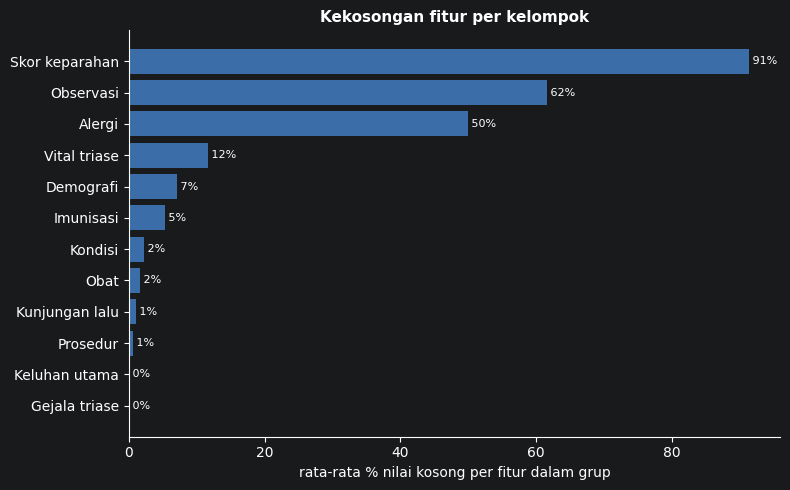

In [33]:
GROUPS = [("vital__", "Vital triase"), ("sym", "Gejala triase"), ("sev", "Skor keparahan"),
          ("cc__", "Keluhan utama"), ("cond", "Kondisi"), ("med", "Obat"), ("proc", "Prosedur"),
          ("imm", "Imunisasi"), ("alg", "Alergi"), ("prev", "Kunjungan lalu"),
          ("obs", "Observasi"), ("age", "Demografi"), ("log_income", "Demografi"),
          ("gender", "Demografi"), ("race", "Demografi"), ("ethnicity", "Demografi"),
          ("state", "Demografi"), ("marital", "Demografi")]
feat_df = train.drop(columns=ID_COLS + [TARGET])
group_name = []
for c in feat_df.columns:
    g = next((lbl for pre, lbl in GROUPS if c.startswith(pre)), "Lainnya")
    group_name.append(g)
miss = pd.DataFrame({"grup": group_name, "kosong": feat_df.isna().mean().values})
summary = miss.groupby("grup")["kosong"].mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(summary.index, summary.values * 100, color="#3b6ea8")
for i, v in enumerate(summary.values):
    ax.text(v * 100, i, f" {v:.0%}", va="center", fontsize=8)
ax.set_xlabel("rata-rata % nilai kosong per fitur dalam grup")
ax.set_title("Kekosongan fitur per kelompok")
plt.tight_layout(); plt.show()

## 8. Pemodelan

### Persiapan matriks

Kolom teks (gender, ras, dan lainnya) dijadikan kategori. Level kategori diambil dari gabungan train dan test, supaya kode yang sama dipakai di kedua data. Ini tidak melihat label, jadi aman.

In [34]:
X = train.drop(columns=ID_COLS + [TARGET])
Xt = test.drop(columns=ID_COLS)
classes = sorted(train[TARGET].unique())
y = train[TARGET].map({c: i for i, c in enumerate(classes)}).values
K = len(classes)

cats = [c for c in X.columns if X[c].dtype == object or str(X[c].dtype).startswith("str")]
for c in cats:
    levels = sorted(set(X[c].dropna()) | set(Xt[c].dropna()))
    dtype = pd.CategoricalDtype(levels)
    X[c] = X[c].astype(dtype)
    Xt[c] = Xt[c].astype(dtype)
Xt = Xt[X.columns]

folds = list(StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED).split(X, y))
print("Kelas:", classes)
print("Fitur:", X.shape[1], "| kolom kategori:", cats)
print("Jumlah fold:", len(folds))

Kelas: ['acute_bronchitis', 'strep_pharyngitis', 'viral_pharyngitis', 'viral_sinusitis']
Fitur: 515 | kolom kategori: ['gender', 'race', 'ethnicity', 'state', 'marital_at_visit']
Jumlah fold: 5


### Baseline: Logistic Regression

Baseline dibuat dulu sebagai pembanding. Jika model yang lebih kompleks tidak lebih baik dari baseline, kompleksitasnya tidak perlu dipertahankan.

Pipeline mengisi nilai kosong dengan median, menstandarkan fitur, lalu melatih regresi logistik dengan bobot kelas seimbang. Semua langkah dihitung ulang di setiap fold, sehingga tidak ada informasi dari fold validasi yang bocor ke fold latih.

In [35]:
Xd = pd.get_dummies(X, columns=cats, dummy_na=True, dtype=float)
lr = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                   LogisticRegression(C=0.5, class_weight="balanced", max_iter=3000))
oof_lr = np.zeros((len(Xd), K))
for tr, va in folds:
    lr.fit(Xd.iloc[tr], y[tr])
    oof_lr[va] = lr.predict_proba(Xd.iloc[va])

lr_f1 = f1_score(y, oof_lr.argmax(1), average="macro")
print(f"Logistic Regression | Macro F1 = {lr_f1:.4f} | log-loss = {log_loss(y, oof_lr):.4f}")

Logistic Regression | Macro F1 = 0.6262 | log-loss = 1.3103


### Pencarian hyperparameter LightGBM

Konfigurasi default dicoba dulu, lalu N_TRIALS - 1 konfigurasi acak dari ruang pencarian kecil. Setiap konfigurasi dievaluasi dengan 5-fold. Early stopping membantu menentukan jumlah pohon yang sesuai di setiap fold.

**Pemilihan memakai log-loss, bukan Macro F1.** Macro F1 dari sekitar 3.600 baris sangat berisik, karena satu prediksi yang berpindah kelas bisa menggeser skor cukup banyak. Log-loss mengukur kualitas probabilitas di semua baris, sehingga lebih stabil untuk memilih model. Aturan ini ditetapkan sebelum melihat perbandingan F1.

In [36]:
t0 = time.time()
rng = np.random.default_rng(SEED)
SPACE = {"num_leaves": [15, 31, 63], "learning_rate": [0.03, 0.05, 0.1],
         "min_child_samples": [10, 20, 40], "feature_fraction": [0.5, 0.7, 0.9],
         "bagging_fraction": [0.6, 0.8, 1.0], "lambda_l2": [0.0, 1.0, 5.0]}
configs = [dict(num_leaves=31, learning_rate=0.05, min_child_samples=20, feature_fraction=0.7,
                bagging_fraction=0.8, lambda_l2=1.0, bagging_freq=1)]
for _ in range(N_TRIALS - 1):
    c = {k: v[rng.integers(len(v))] for k, v in SPACE.items()}
    c["bagging_freq"] = 1
    configs.append(c)

rows, best = [], None
for i, cfg in enumerate(configs):
    oof = np.zeros((len(X), K))
    iters = []
    params = dict(objective="multiclass", num_class=K, metric="multi_logloss",
                  verbosity=-1, seed=SEED, **cfg)
    for tr, va in folds:
        cw = len(tr) / (K * np.bincount(y[tr], minlength=K))
        dtr = lgb.Dataset(X.iloc[tr], y[tr], weight=cw[y[tr]], categorical_feature=cats, free_raw_data=False)
        dva = lgb.Dataset(X.iloc[va], y[va], reference=dtr, categorical_feature=cats, free_raw_data=False)
        b = lgb.train(params, dtr, num_boost_round=800, valid_sets=[dva],
                      callbacks=[lgb.early_stopping(50, verbose=False)])
        oof[va] = b.predict(X.iloc[va], num_iteration=b.best_iteration)
        iters.append(b.best_iteration)
    ll = log_loss(y, oof)
    f1 = f1_score(y, oof.argmax(1), average="macro")
    rows.append({"trial": i, "oof_logloss": round(ll, 5), "oof_macro_f1": round(f1, 4),
                 "iterasi rata-rata": int(np.mean(iters)), **cfg})
    if best is None or ll < best["ll"]:
        best = {"trial": i, "cfg": cfg, "ll": ll, "f1": f1, "oof": oof, "iters": iters}

search = pd.DataFrame(rows).sort_values("oof_logloss").reset_index(drop=True)
print(f"Selesai dalam {time.time() - t0:.0f} detik. Trial terpilih: {best['trial']}")
search.head(12)

Selesai dalam 114 detik. Trial terpilih: 10


,trial,oof_logloss,oof_macro_f1,iterasi rata-rata,num_leaves,learning_rate,min_child_samples,feature_fraction,bagging_fraction,lambda_l2,bagging_freq
0,10,0.50752,0.6694,296,31,0.03,20,0.5,1.0,5.0,1
1,6,0.51045,0.6809,177,31,0.03,10,0.7,1.0,0.0,1
2,0,0.51090,0.6672,138,31,0.05,20,0.7,0.8,1.0,1
3,1,0.52004,0.6822,119,15,0.10,20,0.7,0.8,5.0,1
4,9,0.52056,0.6673,78,63,0.10,40,0.5,0.8,1.0,1
5,2,0.52067,0.6748,130,15,0.10,10,0.5,0.8,5.0,1
6,5,0.52356,0.6655,111,63,0.05,20,0.9,0.8,1.0,1
7,8,0.52517,0.6666,149,63,0.05,10,0.9,0.8,5.0,1
8,3,0.53299,0.6667,60,63,0.10,40,0.9,0.8,0.0,1
9,4,0.53622,0.6636,200,63,0.05,20,0.7,0.6,5.0,1


### Grafik: pencarian hyperparameter

Setiap titik adalah satu konfigurasi. Sumbu horizontal log-loss (makin kecil makin baik), dan sumbu vertikal Macro F1 argmax. Terlihat bahwa Macro F1 dan log-loss tidak selalu searah, sehingga memilih berdasarkan salah satunya perlu dijelaskan.

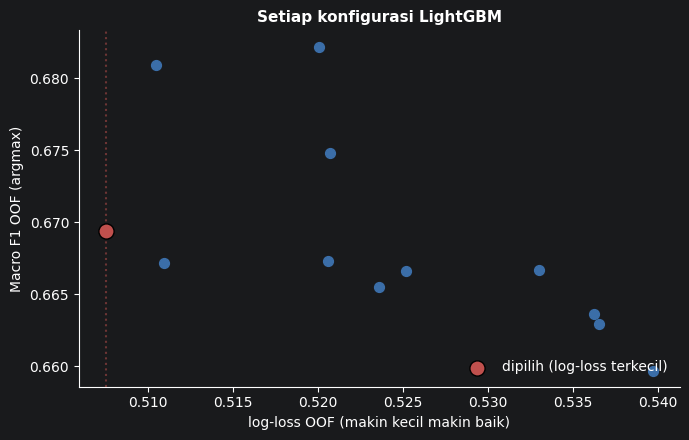

In [37]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(search["oof_logloss"], search["oof_macro_f1"], color="#3b6ea8", s=50)
best_row = search.iloc[0]
ax.scatter([best_row["oof_logloss"]], [best_row["oof_macro_f1"]], color="#c0504d", s=120,
           edgecolor="black", zorder=3, label="dipilih (log-loss terkecil)")
ax.axvline(best_row["oof_logloss"], color="#c0504d", ls=":", alpha=0.5)
ax.set_xlabel("log-loss OOF (makin kecil makin baik)")
ax.set_ylabel("Macro F1 OOF (argmax)")
ax.set_title("Setiap konfigurasi LightGBM")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

### Tuning bobot kelas untuk Macro F1

Probabilitas dikali bobot per kelas sebelum diambil argmax. Bobot dicari dengan coordinate ascent: satu kelas diubah dalam grid, lalu diterima jika Macro F1 naik. Fungsi di sel ini dipakai dua kali, yaitu untuk seluruh OOF dan untuk uji split-half.

In [38]:
def tune_weights(P, y, K, passes=3):
    """Cari bobot per kelas yang memaksimalkan Macro F1 dengan coordinate ascent."""
    w = np.ones(K)
    best_s = f1_score(y, (P * w).argmax(1), average="macro")
    for _ in range(passes):
        for k in range(K):
            for g in GRID:
                w2 = w.copy()
                w2[k] = g
                s = f1_score(y, (P * w2).argmax(1), average="macro")
                if s > best_s + 1e-9:
                    best_s, w = s, w2
    return w, best_s

P = best["oof"]
w, tuned_f1 = tune_weights(P, y, K)
print("Bobot kelas hasil tuning:")
for c, wc in zip(classes, w):
    print(f"  {c:20s} {wc:.3f}")
print(f"\nMacro F1 OOF tanpa tuning : {best['f1']:.4f}")
print(f"Macro F1 OOF dengan tuning: {tuned_f1:.4f} (in-sample, optimistik)")

Bobot kelas hasil tuning:
  acute_bronchitis     0.536
  strep_pharyngitis    1.866
  viral_pharyngitis    0.574
  viral_sinusitis      0.933

Macro F1 OOF tanpa tuning : 0.6694
Macro F1 OOF dengan tuning: 0.6938 (in-sample, optimistik)


### Uji split-half: apakah tuning benar-benar membantu?

Tuning pada seluruh OOF lalu dievaluasi pada data yang sama akan terlihat terlalu bagus. Karena itu, OOF dibagi dua secara acak. Bobot dituning di satu separuh, lalu diuji di separuh lain, dan sebaliknya. Separuh yang diuji tidak pernah dipakai untuk menentukan bobotnya.

In [39]:
rng2 = np.random.default_rng(SEED)
perm = rng2.permutation(len(y))
halves = [perm[: len(y) // 2], perm[len(y) // 2:]]
sh_rows = []
for a, b in [(0, 1), (1, 0)]:
    w_a, _ = tune_weights(P[halves[a]], y[halves[a]], K)
    base = f1_score(y[halves[b]], P[halves[b]].argmax(1), average="macro")
    tuned = f1_score(y[halves[b]], (P[halves[b]] * w_a).argmax(1), average="macro")
    sh_rows.append({"bobot dituning di": f"separuh {a + 1}", "diuji di": f"separuh {b + 1}",
                    "tanpa tuning": round(base, 4), "dengan tuning": round(tuned, 4),
                    "selisih": round(tuned - base, 4)})
sh = pd.DataFrame(sh_rows)
split_gain = sh["selisih"].mean()
print(f"Rata-rata peningkatan split-half: {split_gain:+.4f}")
sh

Rata-rata peningkatan split-half: +0.0129


,bobot dituning di,diuji di,tanpa tuning,dengan tuning,selisih
0,separuh 1,separuh 2,0.6628,0.6729,0.0101
1,separuh 2,separuh 1,0.6755,0.6911,0.0156


### Grafik: dampak bobot kelas per kelas

Bobot kelas diharapkan menaikkan F1 kelas minoritas, yaitu `strep_pharyngitis`, dengan sedikit mengorbankan kelas mayoritas. Grafik berikut membandingkan F1 setiap kelas sebelum dan sesudah tuning.

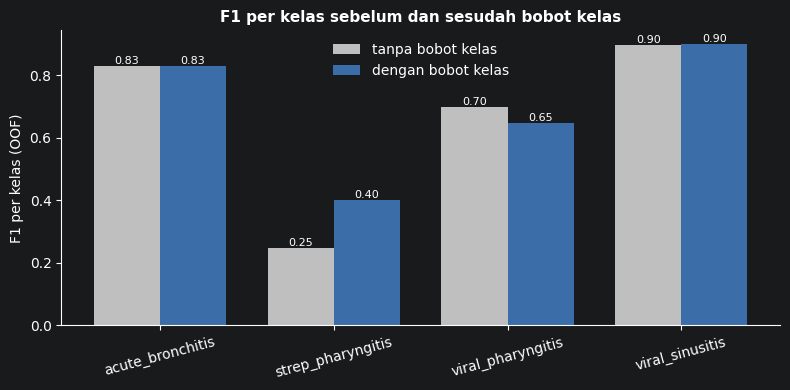

In [40]:
f1_before = f1_score(y, P.argmax(1), average=None)
f1_after = f1_score(y, (P * w).argmax(1), average=None)
x = np.arange(K); wdt = 0.38
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - wdt / 2, f1_before, wdt, label="tanpa bobot kelas", color="#bfbfbf")
ax.bar(x + wdt / 2, f1_after, wdt, label="dengan bobot kelas", color="#3b6ea8")
for i, (a, b_) in enumerate(zip(f1_before, f1_after)):
    ax.text(i - wdt / 2, a, f"{a:.2f}", ha="center", va="bottom", fontsize=8)
    ax.text(i + wdt / 2, b_, f"{b_:.2f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(classes, rotation=15)
ax.set_ylabel("F1 per kelas (OOF)"); ax.set_title("F1 per kelas sebelum dan sesudah bobot kelas")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 9. Evaluasi dan submission

### Perbandingan model

Grafik berikut merangkum skor semua pendekatan. Angka terakhir adalah yang paling jujur, karena dihitung dengan uji split-half.

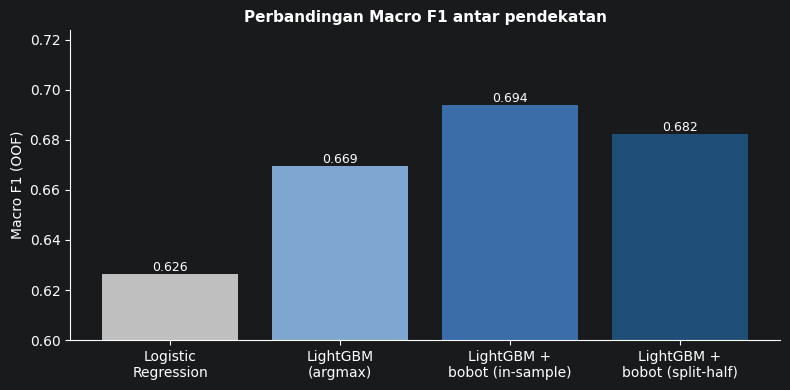

In [41]:
labels_cmp = ["Logistic\nRegression", "LightGBM\n(argmax)", "LightGBM +\nbobot (in-sample)", "LightGBM +\nbobot (split-half)"]
values_cmp = [lr_f1, best["f1"], tuned_f1, best["f1"] + split_gain]
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels_cmp, values_cmp, color=["#bfbfbf", "#7fa6d1", "#3b6ea8", "#1f4e79"])
for b_, v in zip(bars, values_cmp):
    ax.text(b_.get_x() + b_.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0.6, max(values_cmp) + 0.03)
ax.set_ylabel("Macro F1 (OOF)")
ax.set_title("Perbandingan Macro F1 antar pendekatan")
plt.tight_layout(); plt.show()

### Laporan klasifikasi dan matriks kebingungan

Laporan per kelas dan matriks kebingungan dihitung dari OOF setelah bobot diterapkan. Matriks kebingungan menunjukkan kelas mana yang tertukar dengan kelas lain.

                   precision    recall  f1-score   support

 acute_bronchitis      0.839     0.820     0.829       940
strep_pharyngitis      0.313     0.554     0.400       195
viral_pharyngitis      0.729     0.581     0.646       985
  viral_sinusitis      0.879     0.921     0.899      1480

         accuracy                          0.782      3600
        macro avg      0.690     0.719     0.694      3600
     weighted avg      0.797     0.782     0.785      3600



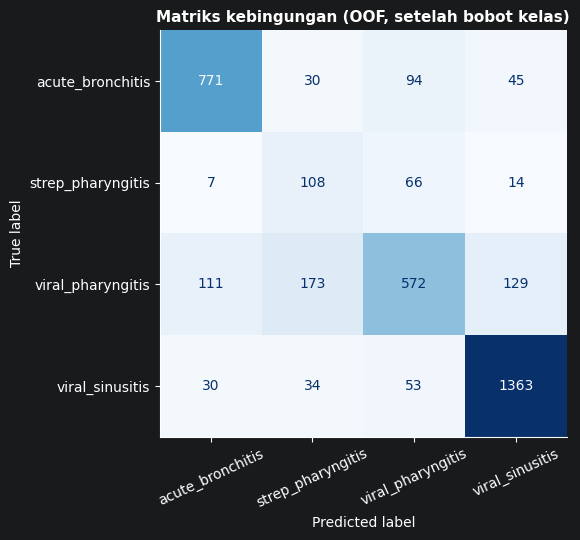

In [42]:
pred_oof = (P * w).argmax(1)
print(classification_report(y, pred_oof, target_names=classes, digits=3, zero_division=0))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(confusion_matrix(y, pred_oof), display_labels=classes).plot(
    ax=ax, cmap="Blues", xticks_rotation=25, colorbar=False)
ax.set_title("Matriks kebingungan (OOF, setelah bobot kelas)")
plt.tight_layout(); plt.show()

**Pembacaan laporan dan matriks.** Angka dari laporan klasifikasi menunjukkan dua hal:
- **Precision strep 0,31**: dari semua prediksi strep, hanya sekitar sepertiga yang benar. Banyak kasus `viral_pharyngitis` masuk ke kelas ini.
- **Recall viral_pharyngitis 0,58**: hampir separuh kasus viral pharyngitis tidak terdeteksi sebagai kelas itu, dan sebagian besar jatuh ke strep.

Kedua kelas ini adalah dua infeksi tenggorokan dengan gejala yang sangat mirip, sehingga pemisahannya sulit hanya dari gejala.

Data tidak memuat hasil tes strep (antigen cepat atau kultur). Tes inilah yang biasanya membedakan kedua kondisi tersebut secara klinis. Ini adalah keterbatasan utama dan bukan sesuatu yang bisa diperbaiki hanya dengan pemodelan.

### Model final dan submission

Model final dilatih ulang di seluruh data train. Jumlah pohon diambil dari rata-rata iterasi terbaik di fold, dinaikkan 10% karena data latihnya lebih banyak. Tiga seed dirata-rata untuk mengurangi variasi acak.

In [43]:
n_rounds = int(np.mean(best["iters"]) * 1.1)
params = dict(objective="multiclass", num_class=K, verbosity=-1, **best["cfg"])
print("Jumlah pohon final:", n_rounds)

Pt = np.zeros((len(Xt), K))
imp = np.zeros(X.shape[1])
for seed in [1, 2, 3]:
    d_all = lgb.Dataset(X, y, weight=(len(y) / (K * np.bincount(y, minlength=K)))[y],
                        categorical_feature=cats, free_raw_data=False)
    m = lgb.train({**params, "seed": seed}, d_all, num_boost_round=n_rounds)
    Pt += m.predict(Xt) / 3
    imp += m.feature_importance("gain") / 3
print("Selesai melatih 3 seed.")

Jumlah pohon final: 326
Selesai melatih 3 seed.


In [44]:
pred = np.array(classes)[(Pt * w).argmax(1)]
sub = pd.DataFrame({"sample_id": test["sample_id"].values, "target_class": pred})

ref = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))[["sample_id"]]
sub = ref.merge(sub, on="sample_id", how="left", validate="one_to_one")
assert sub["target_class"].notna().all(), "ada sample_id tanpa prediksi"
assert len(sub) == len(ref) and sub["sample_id"].is_unique

sub_path = os.path.join(OUT_DIR, "submission.csv")
sub.to_csv(sub_path, index=False)
print("Disimpan:", sub_path, "|", sub.shape)

Disimpan: C:\INAH-MINE\GEMASTIK-XIX\gdgoc_claude\output\submission.csv | (1400, 2)


### Distribusi prediksi test

Distribusi prediksi dibandingkan dengan distribusi train. Kelas `strep_pharyngitis` diprediksi jauh lebih sering (sekitar 12,5% dari test, dibandingkan 5,4% di train). Ini konsekuensi langsung dari bobot kelas: model dibuat lebih berani menebak strep karena Macro F1 memberi bobot yang sama pada setiap kelas. Harga yang dibayar adalah lebih banyak kesalahan pada kelas `viral_pharyngitis`, yang proporsinya turun dari sekitar 27% di train menjadi sekitar 21% di prediksi.

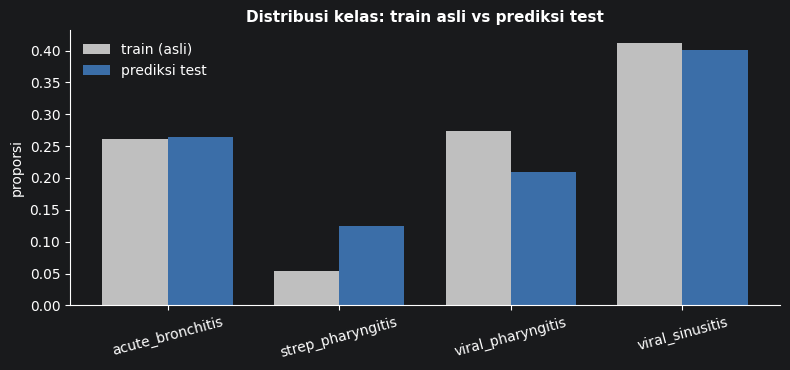

,train,prediksi test
target_class,,
acute_bronchitis,0.261,0.264
strep_pharyngitis,0.054,0.125
viral_pharyngitis,0.274,0.209
viral_sinusitis,0.411,0.401


In [45]:
pred_dist = sub["target_class"].value_counts(normalize=True).reindex(classes)
train_dist = T["train"][TARGET].value_counts(normalize=True).reindex(classes)
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(K); wdt = 0.38
ax.bar(x - wdt / 2, train_dist.values, wdt, label="train (asli)", color="#bfbfbf")
ax.bar(x + wdt / 2, pred_dist.values, wdt, label="prediksi test", color="#3b6ea8")
ax.set_xticks(x); ax.set_xticklabels(classes, rotation=15)
ax.set_ylabel("proporsi"); ax.set_title("Distribusi kelas: train asli vs prediksi test")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
pd.DataFrame({"train": train_dist, "prediksi test": pred_dist}).round(3)

## 10. Interpretasi

Gain dari setiap fitur menunjukkan seberapa besar kontribusinya dalam mengurangi kesalahan model. Ini bukan bukti sebab-akibat, tetapi berguna untuk memeriksa apakah model belajar dari hal yang masuk akal secara klinis.

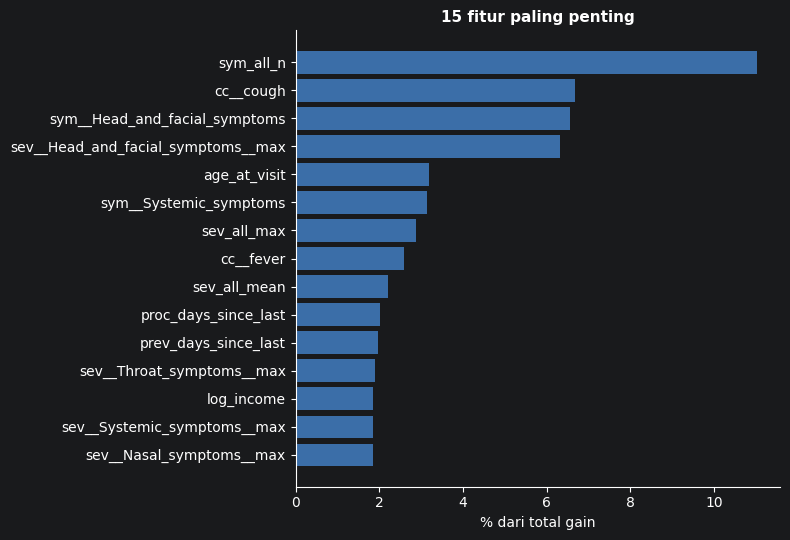

10 fitur teratas menyumbang 46.6% dari total gain


,fitur,persen
0,sym_all_n,11.03
1,cc__cough,6.69
2,sym__Head_and_facial_symptoms,6.56
3,sev__Head_and_facial_symptoms__max,6.32
4,age_at_visit,3.18
5,sym__Systemic_symptoms,3.14
6,sev_all_max,2.87
7,cc__fever,2.60
8,sev_all_mean,2.21
9,proc_days_since_last,2.01


In [46]:
fi = pd.DataFrame({"fitur": X.columns, "gain": imp}).sort_values("gain", ascending=False).reset_index(drop=True)
fi["persen"] = fi["gain"] / fi["gain"].sum() * 100
top = fi.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top["fitur"], top["persen"], color="#3b6ea8")
ax.set_xlabel("% dari total gain")
ax.set_title("15 fitur paling penting")
plt.tight_layout(); plt.show()
print(f"10 fitur teratas menyumbang {fi.head(10)['persen'].sum():.1f}% dari total gain")
fi.head(15)[["fitur", "persen"]].round(2)

**Pembacaan tabel.** Sebagian besar fitur teratas berasal dari gejala triase, yaitu jumlah gejala, batuk, gejala kepala/wajah, dan gejala sistemik. Gejala kepala dan wajah berkaitan dengan sinusitis, sedangkan batuk lebih sering pada bronkitis. Pola ini sejalan dengan logika klinis.

**Peringatan.** Dua fitur riwayat, yaitu `proc_days_since_last` dan `prev_days_since_last`, masuk 10 besar. Keduanya kosong untuk pasien tanpa catatan prosedur atau kunjungan sebelumnya. Model kemungkinan besar memakai **ada atau tidaknya** catatan itu, bukan jarak waktunya. Ini adalah pola yang perlu diwaspadai: sinyalnya nyata di data ini, tetapi maknanya bukan "lama sejak kejadian" seperti yang tertulis di namanya.

## 11. Keterbatasan dan asumsi

Bagian ini mencatat hal-hal yang belum diverifikasi, supaya hasil bisa dinilai dengan tepat.

1. **Hasil tes strep tidak tersedia.** Ini kemungkinan pembatas utama untuk kelas `strep_pharyngitis`.
2. **Keluhan utama tanpa timestamp.** Diasumsikan dicatat saat triase. Asumsi ini masuk akal, tetapi belum bisa dibuktikan dari data.
3. **Rentang nilai klinis** berasal dari pengetahuan umum, bukan dokumen resmi.
4. **Satuan `Body Height`** belum jelas karena campur antara meter dan sentimeter. Kolom ini tidak diberi rentang.
5. **Skor OOF sedikit optimistik.** Early stopping memakai fold validasi, dan bobot dituning di atas OOF. Split-half memberi perkiraan yang lebih jujur, tetapi tetap ada ketidakpastian.
6. **Bobot kelas dipilih dari grid terbatas** (0,5 sampai 2,0). Bobot akhir berada di dalam grid, tetapi pemilihannya tetap berisiko overfit. Split-half adalah pemeriksaan utamanya.
7. **Tidak ada seleksi fitur.** Semua fitur dipakai.
8. **Skor leaderboard** bisa berbeda dari perkiraan, karena skor publik hanya memakai sebagian data uji.

## Ringkasan keputusan

| Keputusan | Pilihan | Alasan | Bukti |
|---|---|---|---|
| Aturan waktu | Same-second | Triase dicatat pada saat prediksi | Selisih 0 sampai 1 detik; strict membuang semua triase |
| Koma pada vital dan observasi | Diubah menjadi titik | Koma di sana adalah desimal | Bagian 4 |
| Koma pada pendapatan | Pemisah ribuan | Format uang | Bagian 5 |
| Nilai tidak masuk akal | Dijadikan kosong | Tidak diketahui apakah salah input atau nilai ekstrem | Bagian 4 |
| Kode jarang | Dibuang (kurang dari 20 kali) | Terlalu jarang untuk dipelajari | Bagian 6 |
| Kota dan county | Dibuang | Kategori terlalu banyak | Bagian 6 |
| Hitungan kosong | Diisi 0 | Berarti "tidak tercatat" | Bagian 6 |
| Jarak waktu kosong | Dibiarkan kosong | 0 berarti "baru saja" dan menyesatkan | Bagian 6 |
| Pemilihan hyperparameter | Log-loss | Lebih stabil daripada Macro F1 | Bagian 8 |
| Bobot kelas | Dituning untuk Macro F1, diuji split-half | Kelas minoritas perlu diperhatikan | Bagian 8 |
| Jumlah pohon final | Rata-rata fold dikali 1,1 | Data latih lebih banyak | Bagian 8 |
| Submission | Urutan sesuai contoh panitia | Menghindari salah format | Bagian 9 |